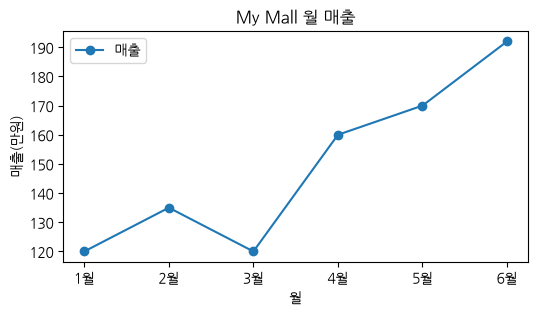

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = "NanumGothic"
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(6, 3))

months = ["1월", "2월", "3월", "4월", "5월", "6월"]
sales = [120, 135, 120, 160, 170, 192]

ax.plot(months, sales, marker="o", label="매출")
ax.set_title("My Mall 월 매출")
ax.set_xlabel("월")
ax.set_ylabel("매출(만원)")
ax.legend()
plt.show()

In [2]:
import pandas as pd
house = pd.read_csv("./datasets/usa_housing.csv")
print(house.shape)
house

(300, 10)


,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
0,221958,1,1.9,4827,1979,2,1.45,82240,48.60,5
1,771155,2,2.0,1035,1987,2,1.75,74315,92.03,9
2,231932,1,3.0,2769,1982,1,1.46,79249,52.08,3
3,465838,3,3.3,2708,1907,3,1.62,80587,61.65,1
4,359178,4,3.4,1175,1994,2,0.74,20756,15.66,4
...,...,...,...,...,...,...,...,...,...,...
295,862002,4,2.8,1129,1944,0,1.80,35227,32.30,3
296,242483,3,2.4,4440,1988,2,0.46,15978,99.71,9
297,758271,2,2.2,4694,1952,2,0.71,97527,97.98,7
298,314835,5,2.0,4907,1941,3,0.53,27153,65.61,8


In [3]:
small = house[(house["YearBuilt"] > 2015) & (house["CrimeRate"] < 40)]
small.shape

(10, 10)

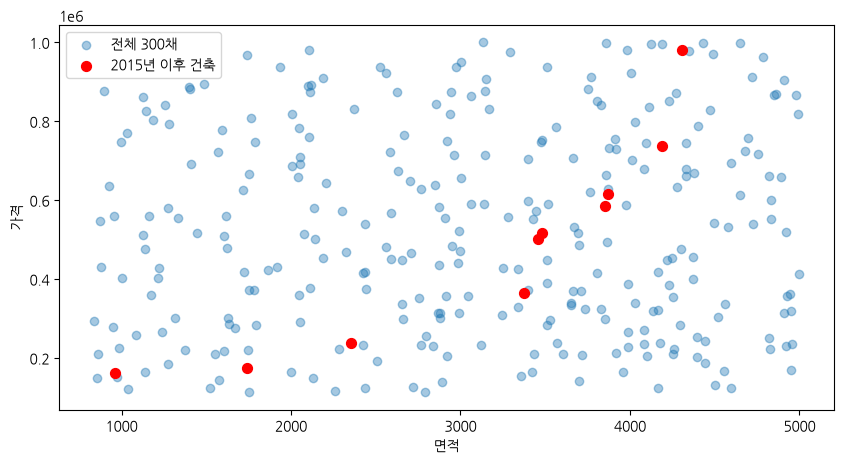

전체 300채의 상관계수: 0.08
10채의 상관계수: 0.89


In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(house["SquareFeet"], house["Price"], alpha=0.4, label="전체 300채") # 산점도
plt.scatter(small["SquareFeet"], small["Price"], color="red", s=50, label="2015년 이후 건축")
plt.xlabel("면적")
plt.ylabel("가격")
plt.legend()
plt.show()

print("전체 300채의 상관계수:", round(house["SquareFeet"].corr(house["Price"]), 2))
print("10채의 상관계수:", round(small["SquareFeet"].corr(small["Price"]), 2))

In [5]:
# 전체 주택과 조건별 주택의 상관계수 비교

# 전체 주택 300채의 상관계수
print("전체 300채의 상관계수:", round(house["SquareFeet"].corr(house["Price"]), 2))

# 2015년 이후 건축 및 범죄율 40 미만인 주택 10채의 상관계수
print("10채의 상관계수:", round(small["SquareFeet"].corr(small["Price"]), 2))

전체 300채의 상관계수: 0.08
10채의 상관계수: 0.89


In [6]:
# RNG: Random Number Generator(난수 생성기)
# 동일한 시드와 호출 순서로 난수를 생성하면 동일한 난수 시퀀스를 얻을 수 있음
rng = np.random.default_rng(40)

n = 200

# 균등분포 Uniform
# rng.uniform(low, high, size)
area = rng.uniform(20, 85, n)
area

array([67.44340219, 65.07197219, 81.22486612, 23.8773839 , 64.8838631 ,
       79.95583874, 50.91940654, 41.99539491, 59.12238234, 67.49080437,
       27.29706864, 27.06083818, 61.42198371, 22.75136689, 23.10137006,
       40.75267887, 33.72835825, 70.45598017, 71.8206861 , 31.16624074,
       29.09989386, 44.0528059 , 54.42670736, 55.25372706, 44.70806217,
       48.05770139, 43.44301317, 37.84361494, 60.34503152, 37.50470026,
       47.21010916, 53.31903146, 39.75568614, 41.72598832, 35.7743788 ,
       37.16783992, 34.77298266, 39.00040215, 65.80622457, 29.39420629,
       60.23622579, 52.40594918, 32.35529271, 41.28840432, 41.52730184,
       39.98670535, 27.28667985, 56.54311059, 59.7731297 , 30.58830963,
       23.4799351 , 51.2199064 , 45.27328164, 28.76196798, 26.61378834,
       83.79071746, 72.04174003, 59.79518218, 47.66635652, 80.70207135,
       57.13772165, 58.83866892, 37.89552816, 56.78872197, 62.80978824,
       68.90370983, 65.40355531, 77.36470817, 25.53958797, 80.15

In [7]:
# 정규분포 Normal
# y = wx + b
# w: 기울기
# b: 절편
# 노이즈를 추가하여 직선 주변에 데이터가 분포하도록 설정

# x축: area, y축: price
# rng.normal(loc, scale, size)
price = (area * 450 + 5000 + (rng.normal(0, 2500, n))).round(-1) # 십의 자리에서 반올림
price

array([37250., 37210., 39420., 15180., 32390., 40460., 29680., 29620.,
       33840., 36950., 11890., 20630., 31150., 17330., 17250., 27190.,
       19490., 37920., 37830., 18530., 20760., 24280., 29180., 31720.,
       28210., 19020., 24910., 21910., 39580., 12340., 26730., 29790.,
       22190., 27280., 21640., 21860., 15280., 23670., 36070., 22380.,
       32650., 33300., 24840., 21930., 26870., 20030., 13670., 32620.,
       33560., 18490., 13170., 24700., 25890., 16570., 19400., 45310.,
       34430., 31140., 24550., 41150., 29510., 28490., 19020., 28200.,
       32360., 30270., 32940., 42290., 17440., 39140., 26460., 27970.,
       38350., 20370., 17990., 42980., 34810., 37770., 21280., 27280.,
       23020., 39160., 38890., 37000., 15960., 19610., 31160., 27450.,
       17560., 37780., 15460., 19770., 29910., 16820., 23040., 24150.,
       27950., 30320., 36930., 26990., 34690., 35420., 30290., 11400.,
       37310., 24970., 41110., 31590., 34040., 35190., 21700., 20830.,
      

In [8]:
# 무작위 표본 추출 Random Sampling
# 특이 매물 5건 생성
special = rng.choice(n, 5, replace=False) # 비복원 추출
price[special] += rng.uniform(15000, 25000, 5).round(-1)
special

array([53, 13,  2, 92, 71])

In [9]:
office = pd.DataFrame({"area": area, "price": price})
office.describe()

,area,price
count,200.000000,200.000000
mean,52.818887,29138.400000
std,18.585307,9112.092603
min,22.044632,11400.000000
25%,37.420928,21615.000000
50%,51.980202,28965.000000
75%,67.426136,36377.500000
max,84.921096,58460.000000


In [10]:
office.to_csv("./datasets/office.csv", index=False)

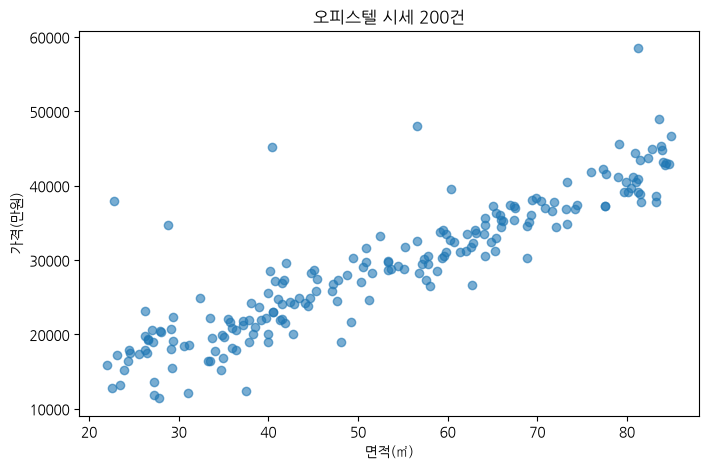

상관계수: 0.8963336215680755


In [11]:
# 산점도 차트

# 캔버스(Figure) 생성
plt.figure(figsize=(8, 5))
plt.scatter(office["area"], office["price"], alpha=0.6)
plt.title("오피스텔 시세 200건")
plt.xlabel("면적(㎡)")
plt.ylabel("가격(만원)")
plt.show()

print("상관계수:", office["area"].corr(office["price"]))

In [12]:
# 선형 회귀 모델 만들기

from sklearn.linear_model import LinearRegression

model = LinearRegression()

X = office[["area"]]
y = office["price"]

model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[439.46]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['area']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5927
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [13]:
print(f"기울기 w = {model.coef_[0]} 정답: 450")
# 기울기 w = 439.45870417134705 정답: 450
print(f"절편 b = {model.intercept_} 정답: 5000")
# 절편 b = 5926.680580056112 정답: 5000

기울기 w = 439.45870417134705 정답: 450
절편 b = 5926.680580056112 정답: 5000


In [14]:
# 33, 59 가격 예측
new = pd.DataFrame({"area": [33, 59]})
model.predict(new).round(-1)

array([20430., 31850.])

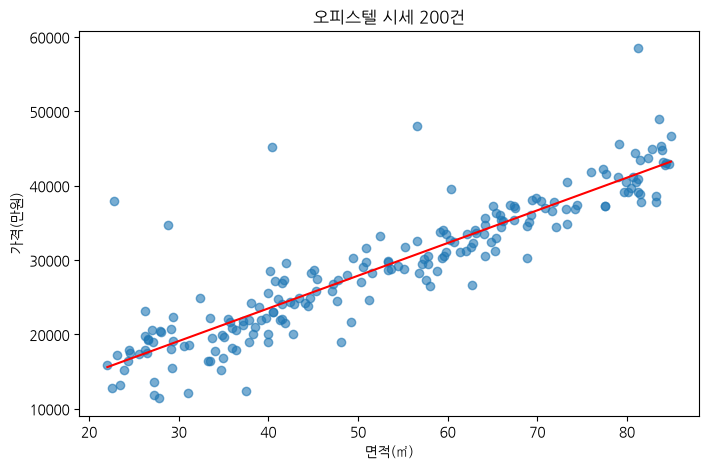

상관계수: 0.8963336215680755


In [16]:
# 학습된 회귀 직선 시각화

# 학습한 모델로 예측하기
y_pred = model.predict(X)
line = X.sort_values("area")
line_pred = model.predict(line)

# 캔버스(Figure) 생성
plt.figure(figsize=(8, 5))
# 산점도 차트
plt.scatter(office["area"], office["price"], alpha=0.6, label="실제 시세")
# 모델의 직선
plt.plot(line["area"], line_pred, color="red", label="회귀 직선")

# 타이틀과 x, y 레이블
plt.title("오피스텔 시세 200건")
plt.xlabel("면적(㎡)")
plt.ylabel("가격(만원)")
plt.show()

print("상관계수:", office["area"].corr(office["price"]))

In [20]:
# 평가 지표 계산

# MAE(평균절대오차), MSE(평균제곱오차), RMSE(평균제곱근오차), R²(결정계수)
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, r2_score

# MAE: 평균 절대 오차 -> 실제값과 예측값의 차이의 절댓값을 평균한 값
print(f"MAE = {mean_absolute_error(y, y_pred):,.0f}")

# MSE: 평균 제곱 오차 -> 실제값과 예측값의 차이의 제곱을 평균한 값
print(f"MSE = {mean_squared_error(y, y_pred):,.0f}")

# RMSE: 평균 제곱근 오차 -> MSE의 제곱근
print(f"RMSE = {root_mean_squared_error(y, y_pred):,.0f}")

# R²: 결정계수 -> 실제값과 예측값의 상관관계를 나타내는 지표(0~1, 음수 가능)
print(f"R_SCORE = {r2_score(y, y_pred):,.3f}")

MAE = 2,493
MSE = 16,240,971
RMSE = 4,030
R_SCORE = 0.803


In [21]:
# 특이 매물 구분과 평가 비교

# np.ones() : 1로 채워진 배열 생성

np.ones(5)
# array([1., 1., 1., 1., 1.])

np.ones(5, dtype=int)
# array([1, 1, 1, 1, 1])

np.ones(5, dtype=bool)
# array([ True,  True,  True,  True,  True])

array([ True,  True,  True,  True,  True])

In [22]:
# 정상 매물과 특이 매물 구분

normal = np.ones(len(office), dtype=bool)
normal[special] = False
print("특이매물", special)
print("정상매물", normal.sum())
normal

특이매물 [53 13  2 92 71]
정상매물 195


array([ True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [23]:
# 특이 매물을 포함했을 때와 제외했을 때의 예측 오차를 비교

all_rows = np.ones(len(office), dtype=bool)
cases = [("전체 200건", all_rows), ("특이매물 제외 195건", normal)]

for name, mask in cases:
    y_true = y[mask]        # 실제 가격
    y_hat = y_pred[mask]    # 예측 가격

    # MAE: 평균 절대 오차
    mae = mean_absolute_error(y_true, y_hat)
    # RMSE: 평균 제곱근 오차
    rmse = root_mean_squared_error(y_true, y_hat)
    # R2: 결정계수
    r2 = r2_score(y_true, y_hat)
    print(f"{name} -> MAE: {mae:,.3f}, RMSE: {rmse:,.3f}, R2: {r2:.4f}")

전체 200건 -> MAE: 2,492.504, RMSE: 4,030.009, R2: 0.8034
특이매물 제외 195건 -> MAE: 2,075.104, RMSE: 2,731.535, R2: 0.9024
